In [1]:
# Configuration: edit this JSON file, then restart the kernel and Run All.
from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "functions.py").is_file() and (p / "applications/configs").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or applications/ folder")
sys.path.insert(0, str(REPO_ROOT))
from reporting import (load_application_config, repo_path, utc_timestamp,
                       select_analysis_window, select_snapshot_time,
                       capture_summary, export_application_results)
CONFIG_PATH = repo_path(REPO_ROOT, globals().get("CONFIG_PATH", REPO_ROOT / "applications/configs/solo.json"))
config = load_application_config(CONFIG_PATH, "solo", REPO_ROOT)
analysis, plot_config = config["analysis"], config["plot"]
outer_fit_kwargs = {"maxfev": config["outer_fit"]["maxfev"], "Rc_max": config["outer_fit"]["Rc_max_m"]}

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import netCDF4 as nc
import xarray as xr
import scipy.io as sio
from datetime import datetime, timedelta

from functions import plot_outer_core_fit, decode_ce23_mat_time, interpolate_satellite_at_time, solo, project_sadcp_to_transect, translate_solo_results, axis_ratio_from_Q, tangential_velocity, out_core_param_fit, model_uv_at_xy, vector_R2 


### SADCP Data

In [2]:
sad = sio.loadmat(repo_path(REPO_ROOT, config["inputs"]["sadcp"]), simplify_cells=True)

z = sad['z_sadcp']
# CE23-specific UTC correction, applied once; raw MAT values are unchanged.
time = decode_ce23_mat_time(sad['tim_sadcp'])

df = pd.DataFrame({
    "Time": time,
    "raw_index": np.arange(time.size),
    "Lon": sad['lon_sadcp'],
    "Lat": sad['lat_sadcp']
})

df = pd.concat([
    df,
    pd.DataFrame(sad['u_sadcp'], index=[f'u_{zv}' for zv in z]).T,
    pd.DataFrame(sad['v_sadcp'], index=[f'v_{zv}' for zv in z]).T
], axis=1)

df = df[df.Lat <= analysis["latitude_max"]].reset_index(drop=True)

theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
df["x"] = (df.Lon-theta_mean)*111000*np.cos(np.deg2rad(phi_mean))
df["y"] = (df.Lat-phi_mean)*111000

ds_sadcp = xr.Dataset(
    {"u": (("time","z"), df[[f"u_{zz}" for zz in z]].to_numpy()),
     "v": (("time","z"), df[[f"v_{zz}" for zz in z]].to_numpy())},
    coords={
        "time": df.Time.values,
        "raw_index": ("time", df.raw_index.values),
        "z": z,
        "lon": ("time", df.Lon.values),
        "lat": ("time", df.Lat.values),
        "x": ("time", df.x.values),
        "y": ("time", df.y.values),
    }
)

# Configured anchor uses the corrected UTC labels; half-window is unchanged.
t0 = utc_timestamp(analysis["transect_center_utc"])
dt = pd.Timedelta(hours=analysis["half_window_hours"])

ds_sadcp = ds_sadcp.sel(time=(ds_sadcp.time >= t0-dt) & (ds_sadcp.time <= t0+dt)).sel(z=analysis["depth_m"], method="nearest")
if not ds_sadcp.sizes["time"]:
    raise ValueError("Configured SOLO selection is empty")
ds_sadcp


<xarray.Dataset> Size: 6kB
Dimensions:    (time: 96)
Coordinates:
  * time       (time) datetime64[ns] 768B 2023-10-17T01:42:30.666659 ... 2023...
    raw_index  (time) int64 768B 775 776 777 778 779 780 ... 866 867 868 869 870
    z          uint16 2B 37
    lon        (time) float64 768B 154.4 154.4 154.4 154.4 ... 154.5 154.5 154.5
    lat        (time) float64 768B -37.1 -37.1 -37.1 ... -38.76 -38.76 -38.76
    x          (time) float64 768B 7.198e+03 7.399e+03 ... 1.985e+04 1.968e+04
    y          (time) float64 768B 8.831e+04 8.833e+04 ... -9.562e+04 -9.556e+04
Data variables:
    u          (time) float64 768B 0.3383 0.3354 0.3216 ... -0.2969 -0.2948
    v          (time) float64 768B -0.06571 -0.03258 ... 0.006335 0.02006

### Satellite data are not required for the SOLO fit

In [3]:
# No satellite input is used by this SOLO example.


### Approximate ESP parameters using SOLO

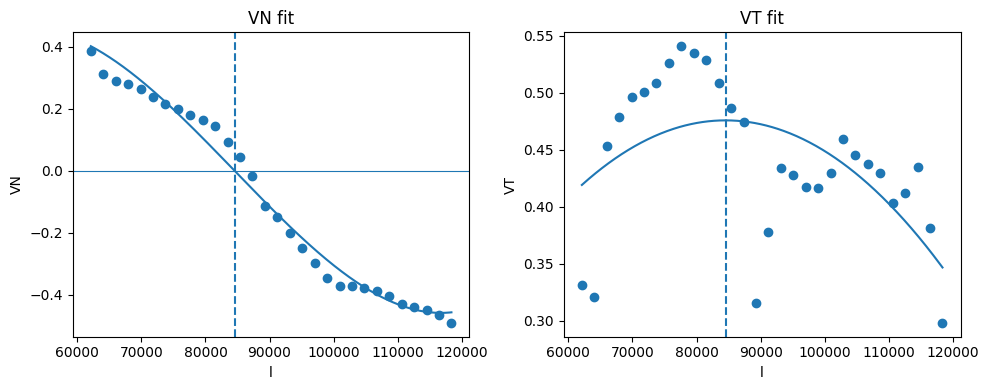

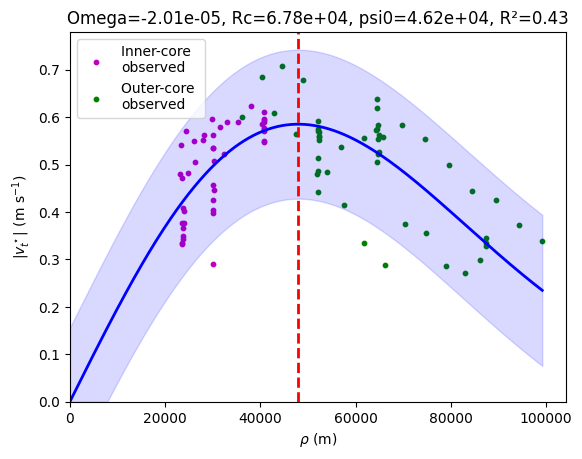

In [4]:
xi, yi, ui, vi = ds_sadcp.x.values, ds_sadcp.y.values, ds_sadcp.u.values, ds_sadcp.v.values

# Project data to transect
df_proj, moca_meta = project_sadcp_to_transect(xi, yi, ui, vi)
# Calculate inner-core ESP parameters
core_thresh = analysis["core_radius_m"]
solo_selection = {}
l0, r0, w, Q, Omega = solo(df_proj.l, df_proj.V_T, df_proj.V_N, plot=plot_config["diagnostics"],
                          selection_details=solo_selection, core_thresh=core_thresh)
# Map the actual along-track fitting window back to the original ADCP points.
l_raw = ((xi - df_proj.iloc[0].x) + moca_meta * (yi - df_proj.iloc[0].y)) / np.sqrt(1 + moca_meta**2)
l_min, l_max = solo_selection["l_bounds"]
core_mask = (l_raw >= l_min) & (l_raw <= l_max)
# Convert transect center coordinates (l0: length along transect, r0: length perpendicular to transect)
# to cartesian coordinates xc, yc
xc, yc = translate_solo_results(df_proj.iloc[0].x, df_proj.iloc[0].y, moca_meta, l0, r0)

# Gather data from beyond the eddy core to estimate outer-core ESP paramters
dx, dy = xi - xc, yi - yc
rho2 = Q[0,0]*dx*dx + 2*Q[1,0]*dx*dy + Q[1,1]*dy*dy
rho_outer = analysis["outer_radius_m"]
outer = rho2 <= rho_outer**2
xi_o, yi_o, ui_o, vi_o = xi[outer], yi[outer], ui[outer], vi[outer]

Omega_core, w_core = Omega, w
outer_fit = {}
Rc, psi0, Omega_opt = out_core_param_fit(
    xi_o, yi_o, ui_o, vi_o, xc, yc, Q, Omega0=Omega, plot=plot_config["diagnostics"],
    km_flag=False, pred_flag=True, fit_details=outer_fit, core_mask=core_mask[outer], **outer_fit_kwargs)

alpha = 1 # calculate axis ratio (assumes axisymmetric)
w = 2.0*Omega_opt # recalculate vorticity with optimal Omega
Omega = Omega_opt

data = {'xc': [xc], 'yc': [yc], 'w': [w], 'Q': [Q], 'alpha': [alpha],
        'Rc': [Rc], 'psi0': [psi0], 'Omega': [Omega],
        'Omega_core': [Omega_core], 'w_core': [w_core], 'fit_status': [outer_fit['status']], 'time': [ds_sadcp.time.mean().values]}
data = pd.DataFrame(data).iloc[0]
df_res = pd.DataFrame(data).T


### Reconstruct the velocity field using the ESP parameters

In [5]:
x = np.linspace(*config["reconstruction"]["x_limits_m"], config["reconstruction"]["grid_points"])
y = np.linspace(*config["reconstruction"]["y_limits_m"], config["reconstruction"]["grid_points"])
X, Y = np.meshgrid(x, y, indexing="xy")

dx, dy = X - data.xc, Y - data.yc
q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]

rho2 = q11*dx*dx + 2*q12*dx*dy + q22*dy*dy

fac = data.Omega * np.exp(-rho2 / data.Rc**2)

U = -fac * (q12*dx + q22*dy)
V =  fac * (q11*dx + q12*dy)

ds_model = xr.Dataset(
    data_vars=dict(
        u=(("y","x"), U),
        v=(("y","x"), V),
    ),
    coords=dict(
        x=("x", x),
        y=("y", y),
        x2d=(("y","x"), X),
        y2d=(("y","x"), Y),
    ),
)

ds_model


<xarray.Dataset> Size: 1MB
Dimensions:  (y: 200, x: 200)
Coordinates:
  * x        (x) float64 2kB -1.5e+05 -1.485e+05 -1.47e+05 ... 1.485e+05 1.5e+05
  * y        (y) float64 2kB -1.5e+05 -1.485e+05 -1.47e+05 ... 1.485e+05 1.5e+05
    x2d      (y, x) float64 320kB -1.5e+05 -1.485e+05 ... 1.485e+05 1.5e+05
    y2d      (y, x) float64 320kB -1.5e+05 -1.5e+05 -1.5e+05 ... 1.5e+05 1.5e+05
Data variables:
    u        (y, x) float64 320kB -0.0002651 -0.0002906 ... 0.0001152 0.0001038
    v        (y, x) float64 320kB 0.0002443 0.0002649 ... -0.0001233 -0.0001122

### Find coefiicient of determination $R^2$ between model and data

In [6]:
df_xyuv = pd.DataFrame({'time': data.time, 'xi': ds_sadcp.x.values, 'yi': ds_sadcp.y.values,
                        'ui': ds_sadcp.u.values, 'vi': ds_sadcp.v.values})

# Find R2
row = df_res.iloc[0]
df = df_xyuv[df_xyuv.time == row.time]
xi = df.xi.to_numpy(float)
yi = df.yi.to_numpy(float)
u  = df.ui.to_numpy(float)
v  = df.vi.to_numpy(float)
uhat, vhat = model_uv_at_xy(xi, yi, row.xc, row.yc, np.asarray(row.Q), row.Omega, row.Rc)
df_res['R2'] = vector_R2(u, v, uhat, vhat)


### Plot results

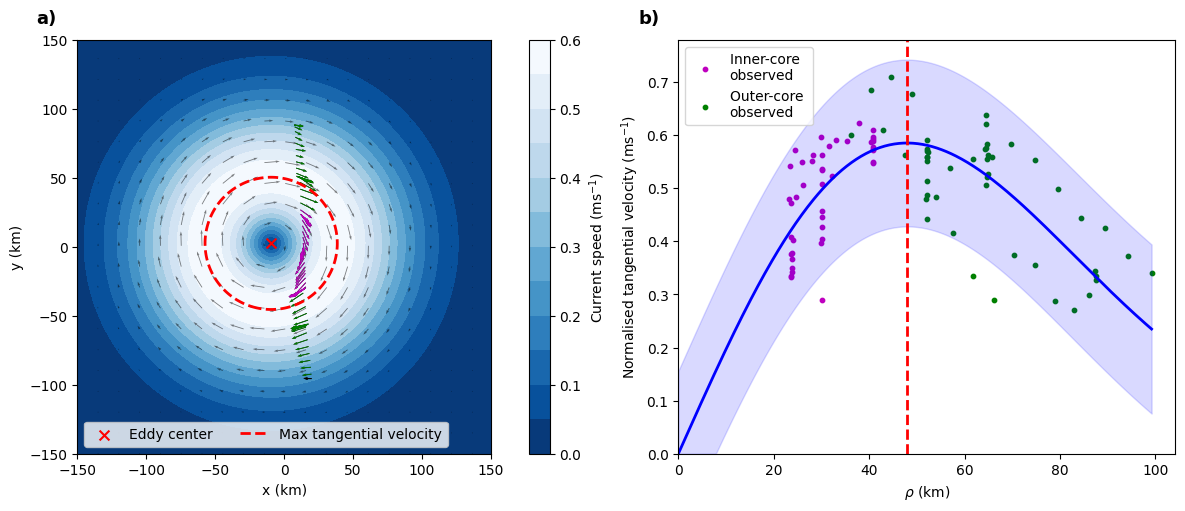

In [7]:
if outer_fit["status"] != "optimized":
    print("SOLO Gaussian figure unavailable: " + outer_fit["status"])
else:
    u = ds_model.u
    v = ds_model.v
    speed = np.hypot(u, v)

    # 1D km coords for plotting
    x = (ds_model.x / 1e3).values
    y = (ds_model.y / 1e3).values

    xmin, xmax = plot_config["x_limits_km"]
    ymin, ymax = plot_config["y_limits_km"]

    # 2D ROI mask (ny, nx)
    Xkm, Ykm = np.meshgrid(x, y, indexing="xy")
    roi = (Xkm >= xmin) & (Xkm <= xmax) & (Ykm >= ymin) & (Ykm <= ymax)

    speed_m = speed.where(roi)

    vmin = float(speed_m.min(skipna=True))
    vmax = float(speed_m.max(skipna=True))
    levels = np.arange(0, vmax+.05, .05)

    fig, axs = plt.subplots(1, 2, figsize=(12,5), constrained_layout=True)

    ax = axs[0]

    # field first (so vectors on top)
    cf = ax.contourf(x, y, speed_m.values, levels=levels, cmap="Blues_r", vmin=vmin, vmax=vmax, zorder=-1)
    fig.colorbar(cf, ax=ax, label=r"Current speed (ms$^{-1}$)")

    spac, scale = plot_config["quiver_spacing"], plot_config["quiver_scale"]
    ax.quiver(x[::spac], y[::spac],
                  u[::spac,::spac], v[::spac,::spac],
                  scale=scale, alpha=.5, width=.002)

    # SADCP vectors (x,y already metres -> convert to km; u,v are m/s)
    ax.quiver(ds_sadcp.x.values/1e3, ds_sadcp.y.values/1e3,
              ds_sadcp.u.values, ds_sadcp.v.values,
              width=.002, scale=scale)

    R = np.hypot(data.xc - ds_sadcp.x.values, data.yc - ds_sadcp.y.values)

    # Reuse the original along-track core window and outer selection.
    outer_mask = outer & ~core_mask

    ax.quiver(ds_sadcp.x.values[core_mask]/1e3, ds_sadcp.y.values[core_mask]/1e3,
              ds_sadcp.u.values[core_mask], ds_sadcp.v.values[core_mask],
              width=.002, scale=scale, color='m')#, label='Core data')

    ax.quiver(ds_sadcp.x.values[outer_mask]/1e3, ds_sadcp.y.values[outer_mask]/1e3,
              ds_sadcp.u.values[outer_mask], ds_sadcp.v.values[outer_mask],
              width=.002, scale=scale, color='g')#, label='Outer-core \ndata') 

    # center
    ax.scatter(xc/1e3, yc/1e3, marker="x", color="r", s=50, label='Eddy center')

    # ellipse contour: compute in metres, but evaluate on the km grid
    Xm = Xkm * 1e3
    Ym = Ykm * 1e3
    dx = Xm - xc
    dy = Ym - yc
    rho2 = Q[0,0]*dx*dx + 2*Q[0,1]*dx*dy + Q[1,1]*dy*dy

    ax.contour(x, y, rho2, levels=[(Rc**2)/2], colors="r", linewidths=2, linestyles='--')
    ax.plot([np.nan, np.nan], [np.nan, np.nan], color='r', ls='--', lw=2, label='Max tangential velocity')

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.legend(loc='lower left', ncol=2)
    ax.text(-0.10, 1.04, 'a)', transform=ax.transAxes, fontsize=13, fontweight='bold')

    ax = axs[1]
    plot_outer_core_fit(outer_fit, ax=ax, km_flag=True, pred_flag=True)

    ax.set_title(''); ax.set_xlabel(r'$\rho$ (km)'); ax.set_ylabel(r'Normalised tangential velocity (ms$^{-1}$)');
    ax.text(-0.08, 1.04, 'b)', transform=ax.transAxes, fontsize=13, fontweight='bold')

    plt.show()


In [8]:
# Results
df_res


,xc,yc,w,Q,alpha,Rc,psi0,Omega,Omega_core,w_core,fit_status,time,R2
0,-9434.639872,2507.191389,-0.00004,"[[1.0, 0.0], [0.0, 1.0]]",1,67805.107217,46249.479018,-0.00002,-0.000021,-0.000043,optimized,2023-10-17 13:35:00.562501250,0.948525


## 3D — exploratory depth tracking

Compare fixed 30/100-km core/outer windows with adaptive 0.5/1.2 times the last supported Gaussian Rc. Both start at 37 m, seeded by the existing surface centre and radius. The outer window also defines the along-track search half-width around the previous accepted centre. A fixed transect frame is used at all depths, projecting actual finite observations without depth interpolation or resampling.

An inner-centre rejection stops that track. Outer-fit failure or lack of observations bracketing the fitted peak leaves reconstruction unavailable, but centre tracking continues. Only a supported outer fit updates the radius used by adaptive selection. Radius is not constrained to decrease. Settings below are exploratory, not a new manuscript method. SOLO imposes circular geometry. The deepest accepted centre is not an estimate of the eddy bottom.


In [9]:
# Isolated controls and variable names: existing surface analysis is unchanged.
import warnings as depth_warnings
DEPTH_SETTINGS = dict(start_m=37., fixed_core_m=20_000., fixed_outer_m=80_000.,
                      core_rc_factor=.5, outer_rc_factor=1.2,
                      max_centre_step_m=30_000., min_points=8,
                      require_peak_bracket=True)
_depth_seed = np.array([float(df_res.iloc[0].xc), float(df_res.iloc[0].yc)])
_depth_initial_rc = float(df_res.iloc[0].Rc)
if not np.isfinite(_depth_initial_rc) or _depth_initial_rc <= 0:
    raise ValueError("Adaptive depth tracking needs a valid surface Rc")
_depth_sign = np.sign(float(df_res.iloc[0].Omega_core))
_depth_origin = df_proj.iloc[0][['x', 'y']].to_numpy(float)
_depth_tangent = np.array([1., moca_meta])/np.sqrt(1+moca_meta**2)
_depth_normal = np.array([-_depth_tangent[1], _depth_tangent[0]])
_depth_indices = ds_sadcp.raw_index.values.astype(int)
_depth_xy = np.column_stack([ds_sadcp.x.values, ds_sadcp.y.values]).astype(float)
_depth_along = (_depth_xy-_depth_origin) @ _depth_tangent
_depth_levels = np.asarray(sad['z_sadcp'], float)
_depth_records = []
depth_samples = {}
for _depth_mode in ('fixed', 'adaptive'):
    _depth_previous = _depth_seed.copy()
    _depth_last_rc = _depth_initial_rc
    _depth_rc_source = DEPTH_SETTINGS['start_m']
    for _depth_j in np.argsort(_depth_levels):
        _depth_z = _depth_levels[_depth_j]
        if _depth_z < DEPTH_SETTINGS['start_m']:
            continue
        _depth_core = (DEPTH_SETTINGS['fixed_core_m'] if _depth_mode == 'fixed'
                       else DEPTH_SETTINGS['core_rc_factor']*_depth_last_rc)
        _depth_outer = (DEPTH_SETTINGS['fixed_outer_m'] if _depth_mode == 'fixed'
                        else DEPTH_SETTINGS['outer_rc_factor']*_depth_last_rc)
        _depth_u = np.asarray(sad['u_sadcp'][_depth_j, _depth_indices], float)
        _depth_v = np.asarray(sad['v_sadcp'][_depth_j, _depth_indices], float)
        _depth_finite = np.isfinite(_depth_xy).all(axis=1) & np.isfinite(_depth_u) & np.isfinite(_depth_v)
        _depth_seed_l = (_depth_previous-_depth_origin) @ _depth_tangent
        _depth_search = _depth_finite & (abs(_depth_along-_depth_seed_l) <= _depth_outer)
        _depth_row = dict(mode=_depth_mode, depth_m=_depth_z, core_window_m=_depth_core,
            outer_window_m=_depth_outer, radius_seed_m=_depth_last_rc,
            radius_seed_depth_m=_depth_rc_source, n_finite=int(_depth_finite.sum()),
            n_search=int(_depth_search.sum()), n_core=0, n_outer=0,
            inner_valid=False, outer_valid=False, status='unattempted',
            xc_m=np.nan, yc_m=np.nan, inner_Omega=np.nan, Omega=np.nan,
            Rc_m=np.nan, candidate_Rc_m=np.nan, centre_step_m=np.nan,
            peak_bracketed=False, vector_R2=np.nan, warnings='')
        _depth_sample = pd.DataFrame(dict(raw_index=_depth_indices,
            x_m=_depth_xy[:,0], y_m=_depth_xy[:,1], u=_depth_u, v=_depth_v,
            finite=_depth_finite, search=_depth_search,
            inner=False, outer_candidate=False, outer_used=False))
        depth_samples[(_depth_mode, float(_depth_z))] = _depth_sample
        try:
            if _depth_search.sum() < DEPTH_SETTINGS['min_points']:
                raise ValueError('insufficient_search_points')
            _depth_l = _depth_along[_depth_search]
            _depth_uv = np.column_stack([_depth_u[_depth_search], _depth_v[_depth_search]])
            _depth_order = np.argsort(_depth_l)
            _depth_details = {}
            with depth_warnings.catch_warnings(record=True) as _depth_caught:
                depth_warnings.simplefilter('always')
                _depth_l0, _depth_r0, _depth_w, _depth_Q, _depth_om = solo(
                    _depth_l[_depth_order], (_depth_uv @ _depth_tangent)[_depth_order],
                    (_depth_uv @ _depth_normal)[_depth_order], core_thresh=_depth_core,
                    selection_details=_depth_details)
            if 'core_mask' in _depth_details:
                _depth_input_indices = np.flatnonzero(_depth_search)[_depth_order]
                _depth_sample.loc[_depth_input_indices, 'inner'] = np.asarray(_depth_details['core_mask'], bool)
                _depth_row['n_core'] = int(_depth_sample['inner'].sum())
            _depth_row['warnings'] = '; '.join(str(w.message) for w in _depth_caught)
            if not np.isfinite([_depth_l0, _depth_r0, _depth_om]).all():
                raise ValueError('nonfinite_inner_fit')
            if not _depth_l.min() < _depth_l0 < _depth_l.max():
                raise ValueError('crossing_outside_observations')
            if _depth_om*_depth_sign <= 0:
                raise ValueError('rotation_reversal')
            _depth_ncore = int(np.asarray(_depth_details['core_mask']).sum())
            _depth_row['n_core'] = _depth_ncore
            if _depth_ncore < DEPTH_SETTINGS['min_points']:
                raise ValueError('insufficient_core_points')
            _depth_centre = _depth_origin + _depth_l0*_depth_tangent + _depth_r0*_depth_normal
            _depth_step = np.linalg.norm(_depth_centre-_depth_previous)
            _depth_row['centre_step_m'] = _depth_step
            if _depth_step > DEPTH_SETTINGS['max_centre_step_m']:
                raise ValueError('centre_jump')
            _depth_row.update(inner_valid=True, xc_m=_depth_centre[0], yc_m=_depth_centre[1],
                              inner_Omega=_depth_om, status='inner_only')
            _depth_previous = _depth_centre.copy()  # Outer failure does not undo this centre.
        except (ValueError, RuntimeError, FloatingPointError, np.linalg.LinAlgError) as _depth_error:
            _depth_row['status'] = str(_depth_error)
            _depth_records.append(_depth_row)
            break
        _depth_radial = np.linalg.norm(_depth_xy-_depth_centre, axis=1)
        _depth_use = _depth_finite & (_depth_radial <= _depth_outer)
        _depth_row['n_outer'] = int(_depth_use.sum())
        _depth_sample['outer_candidate'] = _depth_use
        if _depth_use.sum() >= DEPTH_SETTINGS['min_points']:
            _depth_fit = {}
            with depth_warnings.catch_warnings(record=True) as _depth_caught:
                depth_warnings.simplefilter('always')
                _depth_rc, _depth_psi, _depth_omega = out_core_param_fit(
                    *_depth_xy[_depth_use].T, _depth_u[_depth_use], _depth_v[_depth_use],
                    *_depth_centre, _depth_Q, Omega0=_depth_om,
                    fit_details=_depth_fit, **outer_fit_kwargs)
            _depth_row['warnings'] += '; '.join(str(w.message) for w in _depth_caught)
            _depth_used_indices = np.asarray(_depth_fit.get('observation_indices', []), dtype=int)
            _depth_sample.loc[np.flatnonzero(_depth_use)[_depth_used_indices], 'outer_used'] = True
            _depth_row['candidate_Rc_m'] = _depth_rc
            _depth_rho = np.asarray(_depth_fit['rho'])
            _depth_bracket = bool(len(_depth_rho) and np.isfinite(_depth_rc)
                and _depth_rho.min() < _depth_rc/np.sqrt(2) < _depth_rho.max())
            _depth_row['peak_bracketed'] = _depth_bracket
            _depth_row['status'] = _depth_fit['status']
            if _depth_fit['status'] == 'optimized' and (not DEPTH_SETTINGS['require_peak_bracket'] or _depth_bracket):
                _depth_row.update(outer_valid=True, Rc_m=_depth_rc, Omega=_depth_omega, status='accepted')
                _depth_last_rc, _depth_rc_source = _depth_rc, _depth_z
                _depth_uh, _depth_vh = model_uv_at_xy(*_depth_xy[_depth_use].T,
                    *_depth_centre, _depth_Q, _depth_omega, _depth_rc)
                _depth_row['vector_R2'] = vector_R2(_depth_u[_depth_use], _depth_v[_depth_use], _depth_uh, _depth_vh)
            elif _depth_fit['status'] == 'optimized':
                _depth_row['status'] = 'peak_not_bracketed'
        else:
            _depth_row['status'] = 'insufficient_outer_points'
        _depth_records.append(_depth_row)

depth_results = pd.DataFrame(_depth_records)
depth_results['east_offset_km'] = (depth_results.xc_m-_depth_seed[0])/1000
depth_results['north_offset_km'] = (depth_results.yc_m-_depth_seed[1])/1000
depth_summary = pd.DataFrame([dict(mode=mode, attempted=len(group),
    accepted_centres=int(group.inner_valid.sum()), accepted_outer=int(group.outer_valid.sum()),
    deepest_centre_m=group.loc[group.inner_valid, 'depth_m'].max(),
    last_attempt_m=group.depth_m.iloc[-1], last_status=group.status.iloc[-1])
    for mode, group in depth_results.groupby('mode', sort=False)])
display(depth_summary)
# Export separately from the original surface results.
depth_directory = repo_path(REPO_ROOT, config['output_dir']) / 'depth_exploration'
depth_directory.mkdir(parents=True, exist_ok=True)
depth_results.to_csv(depth_directory / 'depth_fits.csv', index=False)
depth_summary.to_csv(depth_directory / 'tracking_summary.csv', index=False)
import json as depth_json
(depth_directory / 'settings.json').write_text(depth_json.dumps(dict(settings=DEPTH_SETTINGS,
    initial_centre_m=_depth_seed.tolist(), initial_Rc_m=_depth_initial_rc,
    raw_indices=_depth_indices.tolist(), transect_frame='fixed surface projection; actual finite velocity pairs'), indent=2))

# Save the exact masks used by each fit for inspecting selection independently.
depth_selection_table = pd.concat([sample.assign(mode=mode, depth_m=depth)
    for (mode, depth), sample in depth_samples.items()], ignore_index=True)
depth_selection_table.to_csv(depth_directory / 'observation_selection.csv', index=False)


,mode,attempted,accepted_centres,accepted_outer,deepest_centre_m,last_attempt_m,last_status
0,fixed,52,51,51,537.0,547.0,nonfinite_inner_fit
1,adaptive,52,51,51,537.0,547.0,nonfinite_inner_fit


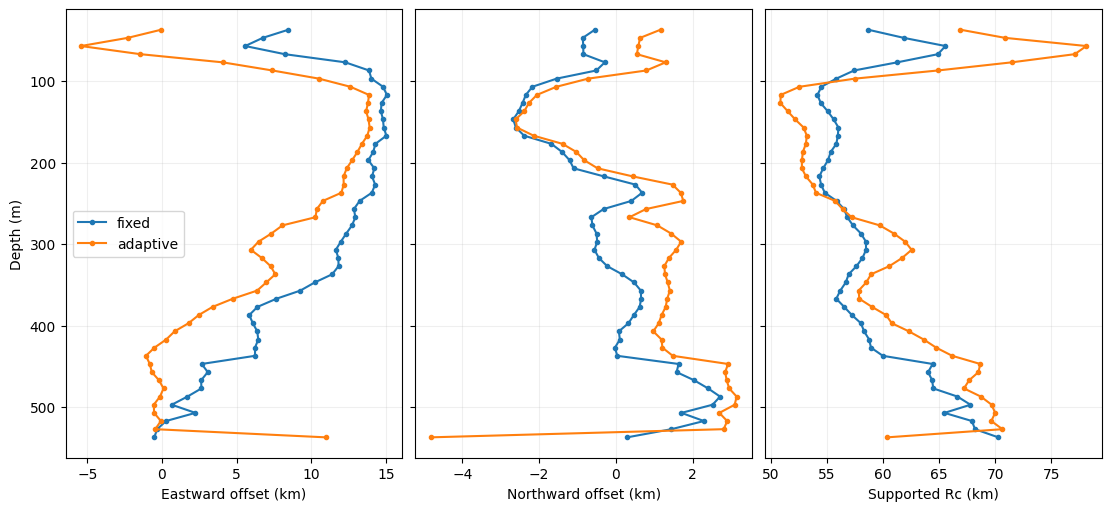

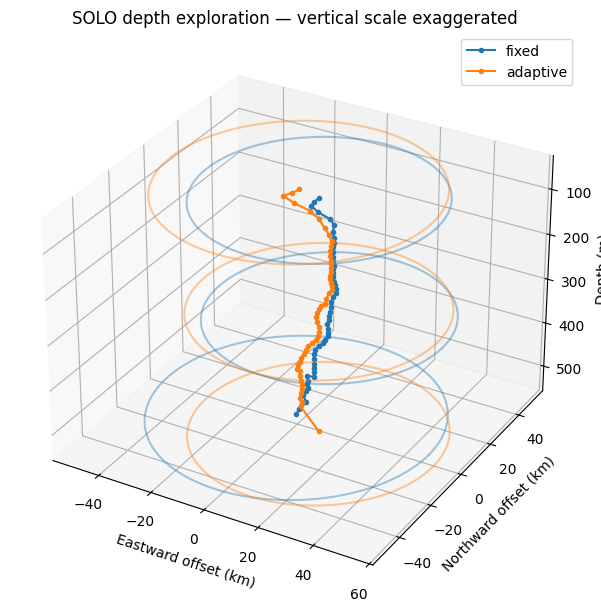

In [10]:
# Profile and 3D diagnostics; two horizontal-map grids follow.
depth_fig_profiles, depth_axes = plt.subplots(1, 3, figsize=(11, 5), sharey=True, constrained_layout=True)
for _depth_mode, _depth_color in [('fixed', 'tab:blue'), ('adaptive', 'tab:orange')]:
    _depth_group = depth_results[depth_results['mode'] == _depth_mode]
    for _depth_ax, _depth_column in zip(depth_axes, ['east_offset_km', 'north_offset_km', 'Rc_m']):
        _depth_values = _depth_group[_depth_column]/(1000 if _depth_column == 'Rc_m' else 1)
        _depth_ax.plot(_depth_values, _depth_group.depth_m, '.-', label=_depth_mode, color=_depth_color)
for _depth_ax, _depth_label in zip(depth_axes, ['Eastward offset (km)', 'Northward offset (km)', 'Supported Rc (km)']):
    _depth_ax.set_xlabel(_depth_label)
    _depth_ax.grid(alpha=.2)
depth_axes[0].set_ylabel('Depth (m)')
depth_axes[0].invert_yaxis()
depth_axes[0].legend()
depth_fig_profiles.savefig(depth_directory / 'depth_profiles.png', dpi=200)

depth_fig_3d = plt.figure(figsize=(8, 6), constrained_layout=True)
depth_ax_3d = depth_fig_3d.add_subplot(111, projection='3d')
_depth_theta = np.linspace(0, 2*np.pi, 150)
for _depth_mode, _depth_color in [('fixed', 'tab:blue'), ('adaptive', 'tab:orange')]:
    _depth_group = depth_results[depth_results['mode'] == _depth_mode]
    depth_ax_3d.plot(_depth_group.east_offset_km, _depth_group.north_offset_km,
                    _depth_group.depth_m, '.-', color=_depth_color, label=_depth_mode)
    _depth_supported = _depth_group[_depth_group.outer_valid]
    if len(_depth_supported):
        for _depth_index in np.unique(np.linspace(0, len(_depth_supported)-1, min(3, len(_depth_supported))).astype(int)):
            _depth_row = _depth_supported.iloc[_depth_index]
            _depth_r = _depth_row.Rc_m/np.sqrt(2)/1000
            depth_ax_3d.plot(_depth_row.east_offset_km+_depth_r*np.cos(_depth_theta),
                _depth_row.north_offset_km+_depth_r*np.sin(_depth_theta),
                np.full_like(_depth_theta, _depth_row.depth_m), color=_depth_color, alpha=.4)
depth_ax_3d.set(xlabel='Eastward offset (km)', ylabel='Northward offset (km)', zlabel='Depth (m)',
                title='SOLO depth exploration — vertical scale exaggerated')
depth_ax_3d.invert_zaxis()
depth_ax_3d.legend()
depth_fig_3d.savefig(depth_directory / 'depth_structure.png', dpi=200)


### Horizontal reconstructions
Two 2×4 grids compare identical measured depths. Masks are recorded during fitting, including the shared outer fitter’s retained-observation indices. Inner colouring takes priority for overlapping selections. Failed and unattempted depths remain visible without reconstructed flow.

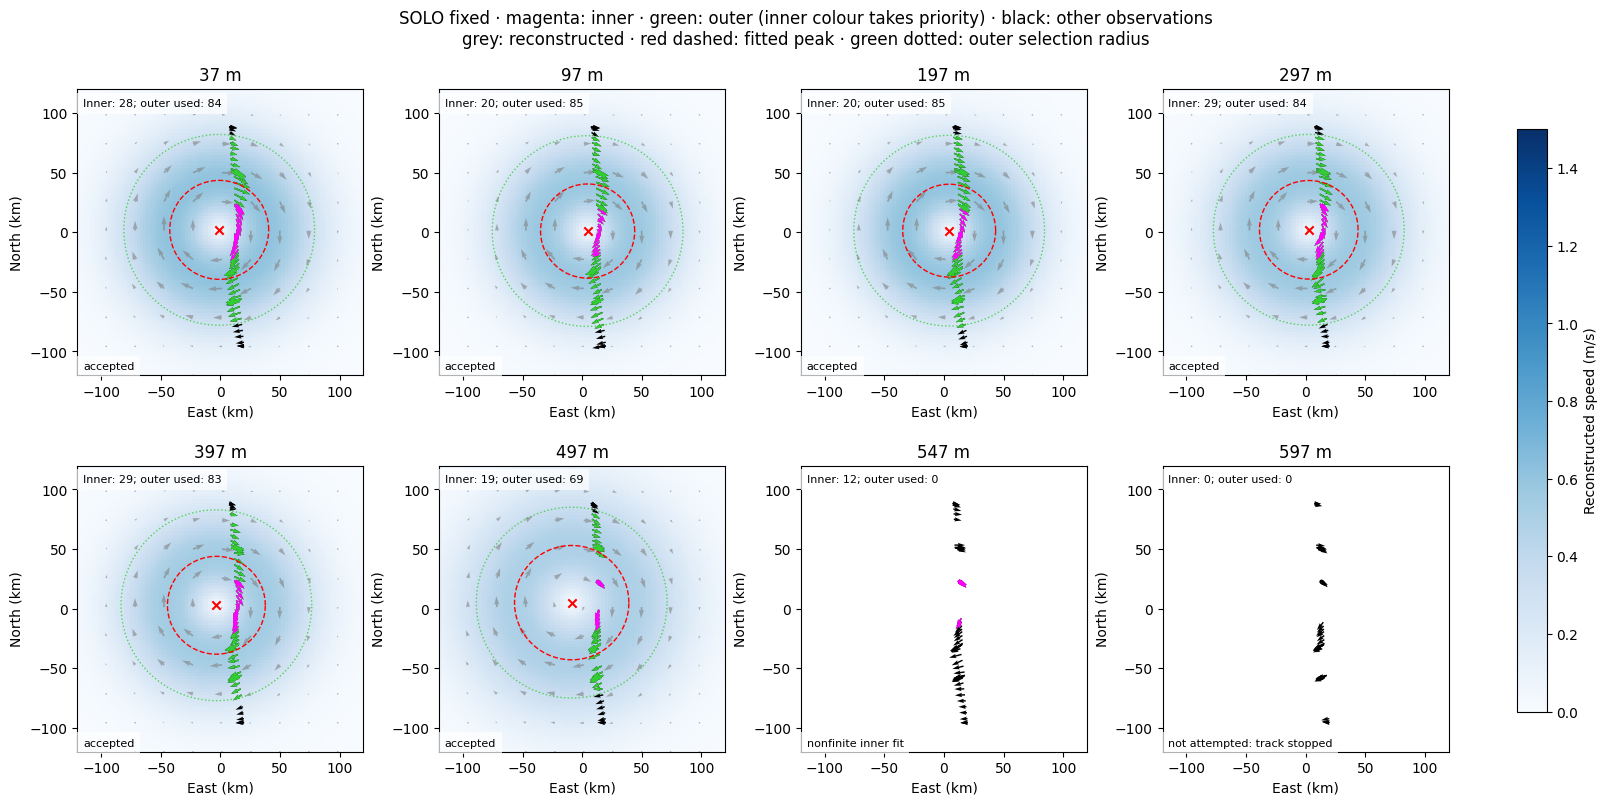

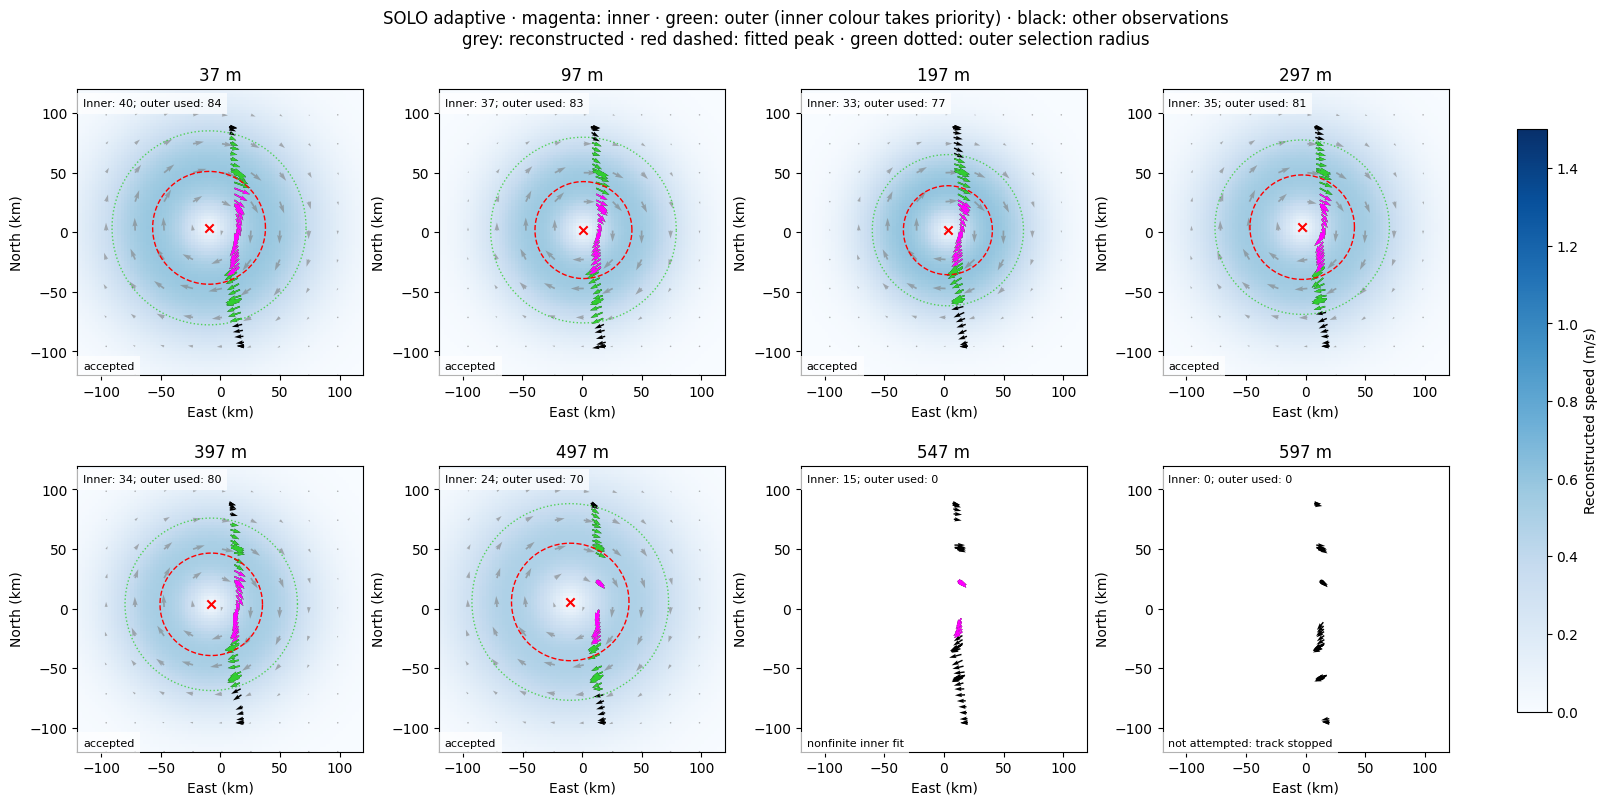

In [11]:
# Shared requested depths; select the nearest measured bin, never the nearest valid fit.
DEPTH_MAP_DEPTHS = (37, 100, 200, 300, 400, 500, 550, 600)
DEPTH_MAP_HALF_WIDTH_KM = 120.
DEPTH_MAP_SPEED_MAX = 1.5
_depth_map_levels = _depth_levels[_depth_levels >= DEPTH_SETTINGS['start_m']]
depth_map_levels = [float(_depth_map_levels[np.argmin(abs(_depth_map_levels-z))]) for z in DEPTH_MAP_DEPTHS]
if len(depth_map_levels) != 8 or len(set(depth_map_levels)) != 8:
    raise ValueError('Choose eight distinct measured depths for the 2×4 maps')
_depth_map_axis = np.linspace(-DEPTH_MAP_HALF_WIDTH_KM, DEPTH_MAP_HALF_WIDTH_KM, 90)
_depth_map_x, _depth_map_y = np.meshgrid(_depth_map_axis*1000, _depth_map_axis*1000)
_depth_map_theta = np.linspace(0, 2*np.pi, 200)
depth_map_figures = {}
for _depth_map_mode in ('fixed', 'adaptive'):
    _depth_map_fig, _depth_map_axes = plt.subplots(2, 4, figsize=(16, 8),
                                                constrained_layout=True)
    for _depth_map_ax, _depth_map_z in zip(_depth_map_axes.flat, depth_map_levels):
        _depth_map_rows = depth_results[(depth_results['mode'] == _depth_map_mode) &
                                       (depth_results.depth_m == _depth_map_z)]
        _depth_map_row = None if _depth_map_rows.empty else _depth_map_rows.iloc[0]
        _depth_map_sample = depth_samples.get((_depth_map_mode, _depth_map_z))
        if _depth_map_sample is None:
            # Show actual observations even below the stopping depth; no fit is invented.
            _depth_map_j = int(np.flatnonzero(_depth_levels == _depth_map_z)[0])
            _depth_map_sample = pd.DataFrame(dict(x_m=_depth_xy[:,0], y_m=_depth_xy[:,1],
                u=np.asarray(sad['u_sadcp'][_depth_map_j, _depth_indices]),
                v=np.asarray(sad['v_sadcp'][_depth_map_j, _depth_indices]),
                inner=False, outer_used=False))
        _depth_map_finite = np.isfinite(_depth_map_sample[['x_m','y_m','u','v']]).all(axis=1)
        if _depth_map_row is not None and _depth_map_row.outer_valid:
            _depth_map_uh, _depth_map_vh = model_uv_at_xy(_depth_map_x, _depth_map_y,
                _depth_map_row.xc_m, _depth_map_row.yc_m, np.eye(2),
                _depth_map_row.Omega, _depth_map_row.Rc_m)
            _depth_map_ax.pcolormesh(_depth_map_axis, _depth_map_axis,
                np.hypot(_depth_map_uh, _depth_map_vh), vmin=0, vmax=DEPTH_MAP_SPEED_MAX,
                cmap='Blues', shading='auto')
            _depth_map_ax.quiver(_depth_map_x[::9,::9]/1000, _depth_map_y[::9,::9]/1000,
                _depth_map_uh[::9,::9], _depth_map_vh[::9,::9], scale=12, color='grey', alpha=.6)
            _depth_map_radius = _depth_map_row.Rc_m/np.sqrt(2)/1000
            _depth_map_ax.plot(_depth_map_row.xc_m/1000+_depth_map_radius*np.cos(_depth_map_theta),
                _depth_map_row.yc_m/1000+_depth_map_radius*np.sin(_depth_map_theta), 'r--', lw=1)
        # Inner selection has colour priority where observations enter both fits.
        for _depth_map_mask, _depth_map_color in [(_depth_map_finite, 'black'),
                (_depth_map_finite & _depth_map_sample.outer_used, 'limegreen'),
                (_depth_map_finite & _depth_map_sample.inner, 'magenta')]:
            _depth_map_points = _depth_map_sample.loc[_depth_map_mask]
            _depth_map_ax.quiver(_depth_map_points.x_m/1000, _depth_map_points.y_m/1000,
                _depth_map_points.u, _depth_map_points.v, scale=12, color=_depth_map_color, width=.005)
        if _depth_map_row is not None and _depth_map_row.inner_valid:
            _depth_map_ax.scatter(_depth_map_row.xc_m/1000, _depth_map_row.yc_m/1000,
                                  marker='x', color='red', zorder=5)
            # Actual outer selection radius, distinct from the fitted peak contour.
            _depth_map_radius = _depth_map_row.outer_window_m/1000
            _depth_map_ax.plot(_depth_map_row.xc_m/1000+_depth_map_radius*np.cos(_depth_map_theta),
                _depth_map_row.yc_m/1000+_depth_map_radius*np.sin(_depth_map_theta),
                color='limegreen', ls=':', lw=1, alpha=.8)
        _depth_map_status = ('not attempted: track stopped' if _depth_map_row is None
                             else _depth_map_row.status.replace('_', ' '))
        _depth_map_ax.text(.02, .02, _depth_map_status, transform=_depth_map_ax.transAxes,
                           fontsize=8, bbox=dict(facecolor='white', alpha=.7, edgecolor='none'))
        _depth_map_ax.set(xlim=(-DEPTH_MAP_HALF_WIDTH_KM, DEPTH_MAP_HALF_WIDTH_KM),
            ylim=(-DEPTH_MAP_HALF_WIDTH_KM, DEPTH_MAP_HALF_WIDTH_KM), aspect='equal',
            xlabel='East (km)', ylabel='North (km)', title=f'{_depth_map_z:g} m')
        _depth_map_ax.text(.02, .94,
            f"Inner: {int(_depth_map_sample.inner.sum())}; outer used: {int(_depth_map_sample.outer_used.sum())}",
            transform=_depth_map_ax.transAxes, fontsize=8,
            bbox=dict(facecolor='white', alpha=.7, edgecolor='none'))
    from matplotlib.cm import ScalarMappable as DepthScalarMappable
    from matplotlib.colors import Normalize as DepthNormalize
    _depth_map_fig.colorbar(DepthScalarMappable(norm=DepthNormalize(0, DEPTH_MAP_SPEED_MAX), cmap='Blues'),
        ax=list(_depth_map_axes.flat), label='Reconstructed speed (m/s)', shrink=.8)
    _depth_map_fig.suptitle(f'SOLO { _depth_map_mode } · magenta: inner · green: outer (inner colour takes priority) · black: other observations\n'
        'grey: reconstructed · red dashed: fitted peak · green dotted: outer selection radius')
    _depth_map_fig.savefig(depth_directory / f'horizontal_reconstructions_{_depth_map_mode}.png', dpi=200)
    depth_map_figures[_depth_map_mode] = _depth_map_fig


### Manuscript results summary
Computed from this run. All dates are UTC; final refined parameters are reported.
This notebook demonstrates ESP on real data; idealised experiments are outside its scope.

In [12]:
with capture_summary() as manuscript_text:
    from reporting import print_manuscript_summary, fit_record, evaluation_counts

    summary_counts = pd.DataFrame([{
        "source": "sadcp", "original_observations": ds_sadcp.sizes["time"],
        "resampled_transect_points": len(df_proj),
        "resampled_inner_fit_points": int(solo_selection["core_mask"].sum()),
        "original_points_in_core_window": int(core_mask.sum()),
        "outer_candidates": int(outer.sum()), "outer_fit_n": len(outer_fit["rho"]),
        "velocity_R2_n": int(evaluation_counts(df_xyuv).velocity_R2_n.sum()),
    }])
    print_manuscript_summary(
        "SOLO — S-ADCP", df_res.assign(source="sadcp"),
        {"Original observation interval": f"{ds_sadcp.time.values[0]} to {ds_sadcp.time.values[-1]} UTC",
         "Observation duration (hours)": (ds_sadcp.time.values[-1] - ds_sadcp.time.values[0]) / np.timedelta64(1, "h"),
         "Mean observation time": f"{ds_sadcp.time.mean().values} UTC",
         "Selection anchor / half-window": f"{t0} UTC / {dt}",
         "Depth (m)": float(ds_sadcp.z),
         "MAT UTC correction": "-12 h, applied once to MAT-derived labels",
         "Local origin (longitude, latitude)": (theta_mean, phi_mean),
         "Inner along-track half-width (km)": core_thresh / 1000,
         "Outer elliptical radius limit (km)": rho_outer / 1000},
        counts=summary_counts,
        outer_records=[fit_record(df_res.iloc[0].time, outer_fit, "sadcp")],
        notes=["Velocity R² uses all original selected ADCP pairs, not just the outer fit.",
               "The inner fit uses resampled transect points; original-point colour counts are different.",
               "Shading is an approximate 95% prediction interval; space/time correlation is ignored."],
        input_files=["applications/SOLO_transect_data.ipynb", *config["inputs"].values()], root=REPO_ROOT)

export_directory = export_application_results(
    REPO_ROOT, CONFIG_PATH, config,
    df_res, manuscript_text.getvalue(),
    notebook="applications/SOLO_transect_data.ipynb",
    tables={"observation_counts": summary_counts, "outer_fit_diagnostics": pd.DataFrame([fit_record(df_res.iloc[0].time, outer_fit, "sadcp")])},
    run_info={"raw_adcp_indices": ds_sadcp.raw_index.values, "mean_adcp_time_utc": ds_sadcp.time.mean().values})



MANUSCRIPT RESULTS SUMMARY — SOLO — S-ADCP
Current run; compare with the manuscript after any analysis change. All times UTC.

DATA AND SETTINGS
  Original observation interval: 2023-10-17T01:42:30.666659000 to 2023-10-18T01:27:30.333340000 UTC
  Observation duration (hours): 23.74990741138889
  Mean observation time: 2023-10-17T13:35:00.562501250 UTC
  Selection anchor / half-window: 2023-10-17 13:30:00 UTC / 0 days 12:00:00
  Depth (m): 37.0
  MAT UTC correction: -12 h, applied once to MAT-derived labels
  Local origin (longitude, latitude): (154.3, -37.9)
  Inner along-track half-width (km): 30.0
  Outer elliptical radius limit (km): 100.0

MANUSCRIPT-ROUNDED VALUES (final refined Omega; omega = Omega tr(Q))
  sadcp, 2023-10-17 13:35:00.562501250 UTC: (x0,y0)=(-9.4, 2.5) km; omega=-4.0e-05 s^-1; Omega=-2.0e-05 s^-1; alpha=1.00; Rc=67.8 km; psi0=46249.5 m^2/s; R²_velocity=0.95

NUMERICAL RESULTS (additional precision, not physical measurement accuracy)
source                        